# Food Image Classifier

TME 6015 Assignment 2. The task is to classify recipe blog photos into six classes: cake, cookies, pasta, salad, soup and stir_fry.

The notebook trains three models on the same data:

1. **Model 0:** a naive baseline with one conv block.
2. **Model 1:** a CNN built from scratch for this dataset.
3. **Model 2:** transfer learning from a pre-trained backbone.

Sections 1 to 3 hold everything the models share: data loading, class weights, augmentation, training and evaluation. Every model trains through the same function, so differences in results come from the architecture and not the setup. Tuning uses the validation set only. Each model touches the test set once, after its tuning is done.

## 1. Setup

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import tensorflow as tf
from sklearn.metrics import ConfusionMatrixDisplay, accuracy_score, classification_report, f1_score
from tensorflow.keras import layers

In [2]:
ROOT = Path.cwd()  # the notebook runs from the repo root
SPLIT = ROOT / "data" / "split"
CLASS_NAMES = ["cake", "cookies", "pasta", "salad", "soup", "stir_fry"]
NUM_CLASSES = len(CLASS_NAMES)
IMG_SIZE = (224, 224)
INPUT_SHAPE = IMG_SIZE + (3,)
BATCH_SIZE = 32
SEED = 42

tf.keras.utils.set_random_seed(SEED)

## 2. Data

### 2.1 Loading

The split script wrote one folder per class inside `train/`, `val/` and `test/`. `image_dataset_from_directory` reads the folder names as labels.

- `class_names` fixes the label order, so label 0 means cake in every split.
- `crop_to_aspect_ratio=True` takes a centre crop before resizing. Most photos are portrait (aspect ratio about 0.7), and a plain resize would squash them.
- Pixels stay in the 0 to 255 range. Each model scales its own input, because the scratch CNN and the pre-trained backbone expect different ranges.
- The loader caches decoded images after the first epoch. The training set is shuffled after the cache, so the batches change every epoch. Shuffling before the cache would freeze the batch order after epoch 1.
- Validation and test keep a fixed order, so predictions line up with labels and file names during evaluation.

In [3]:
def load(split, training=False):
    ds = tf.keras.utils.image_dataset_from_directory(
        SPLIT / split,
        class_names=CLASS_NAMES,
        label_mode="int",
        image_size=IMG_SIZE,
        crop_to_aspect_ratio=True,
        batch_size=None,
        shuffle=False,
    )
    files = ds.file_paths
    ds = ds.cache()
    if training:
        ds = ds.shuffle(len(files), seed=SEED)
    return ds.batch(BATCH_SIZE).prefetch(tf.data.AUTOTUNE), files


train_ds, train_files = load("train", training=True)
val_ds, val_files = load("val")
test_ds, test_files = load("test")

train_ds.element_spec

Found 1175 files belonging to 6 classes.
Found 252 files belonging to 6 classes.
Found 252 files belonging to 6 classes.


(TensorSpec(shape=(None, 224, 224, 3), dtype=tf.float32, name=None),
 TensorSpec(shape=(None,), dtype=tf.int32, name=None))

### 2.2 Sanity check

One batch of training images with their labels. This confirms that the labels match the images and that the centre crop keeps the food in frame.

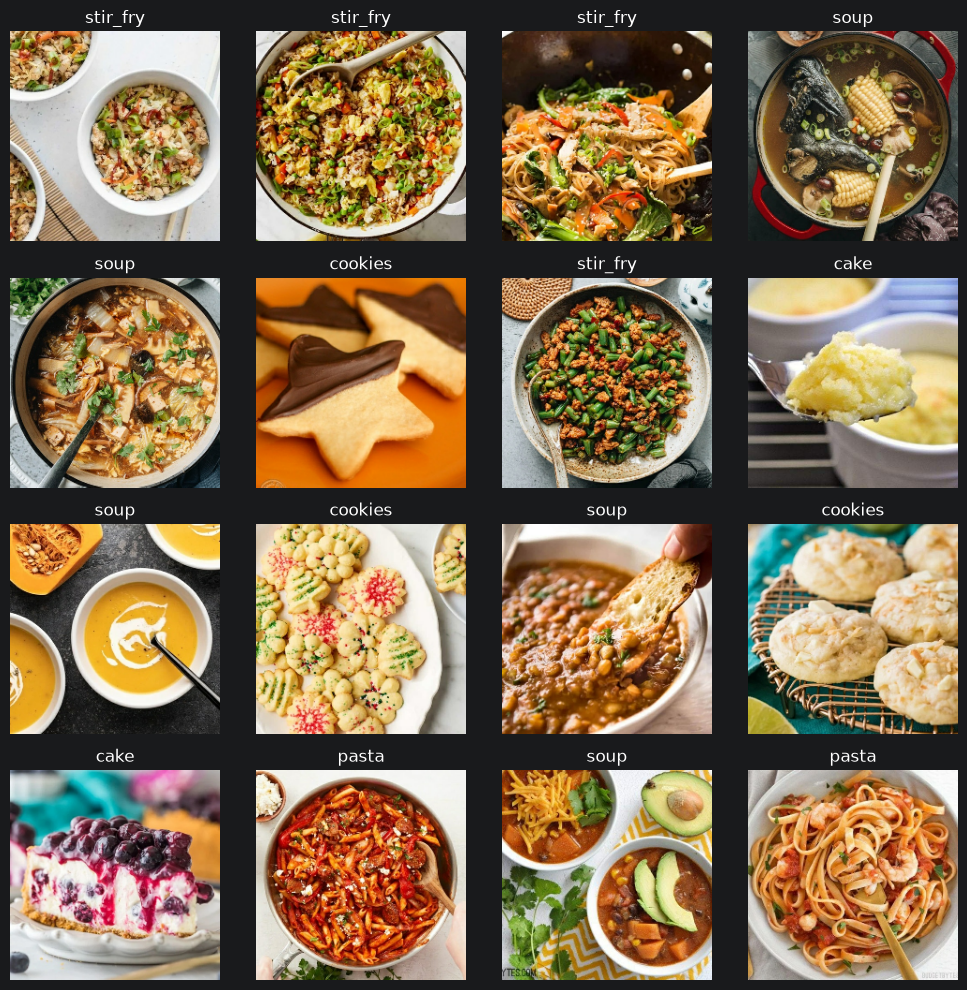

In [4]:
def show_images(images, titles, cols=4):
    rows = int(np.ceil(len(titles) / cols))
    plt.figure(figsize=(2.5 * cols, 2.5 * rows))
    for i, title in enumerate(titles):
        plt.subplot(rows, cols, i + 1)
        plt.imshow(np.asarray(images[i]).astype("uint8"))
        plt.title(title)
        plt.axis("off")
    plt.tight_layout()
    plt.show()


images, labels = next(iter(train_ds))
show_images(images, [CLASS_NAMES[i] for i in labels[:16]])

### 2.3 Class weights

Stir fry has about two thirds as many training images as the other classes. Without a correction the model gains less from learning it. Each class weight is `total / (classes × class count)`, the same formula as sklearn's `"balanced"` option. A class of average size gets a weight of 1, and smaller classes get more. The weights come from the training set only.

The same imbalance is why macro F1 is the main metric alongside accuracy. It averages F1 over classes, so stir fry counts as much as soup.

In [5]:
train_counts = {i: len(list((SPLIT / "train" / name).glob("*.jpg"))) for i, name in enumerate(CLASS_NAMES)}
total = sum(train_counts.values())
class_weight = {i: total / (NUM_CLASSES * count) for i, count in train_counts.items()}

pd.DataFrame({
    "class": CLASS_NAMES,
    "train images": train_counts.values(),
    "weight": [round(w, 2) for w in class_weight.values()],
})

,class,train images,weight
0,cake,210,0.93
1,cookies,202,0.97
2,pasta,204,0.96
3,salad,210,0.93
4,soup,210,0.93
5,stir_fry,139,1.41


## 3. Shared components

### 3.1 Augmentation

With about 200 images per class, a model can memorise the training photos within a few epochs. Random changes give it a slightly different version of each photo every epoch, so it has to learn what the food looks like instead of the exact pixels.

- **Horizontal flip:** a mirrored dish is still the same dish. No vertical flip, since upside down plates do not appear in blog photos.
- **Rotation up to 18 degrees:** covers a tilted camera.
- **Zoom up to 10%:** covers close ups against wide table shots, which differ a lot between sites.
- **Contrast up to 10%:** covers different lighting and editing styles. Each blog has its own look, so this also weakens site style as a shortcut.

The changes stay mild because strong augmentation on a small dataset can make training images harder than the real ones. Keras random layers only run during `fit`, so validation and test images pass through unchanged. The block works on raw 0 to 255 pixels and sits at the front of any model that uses it.

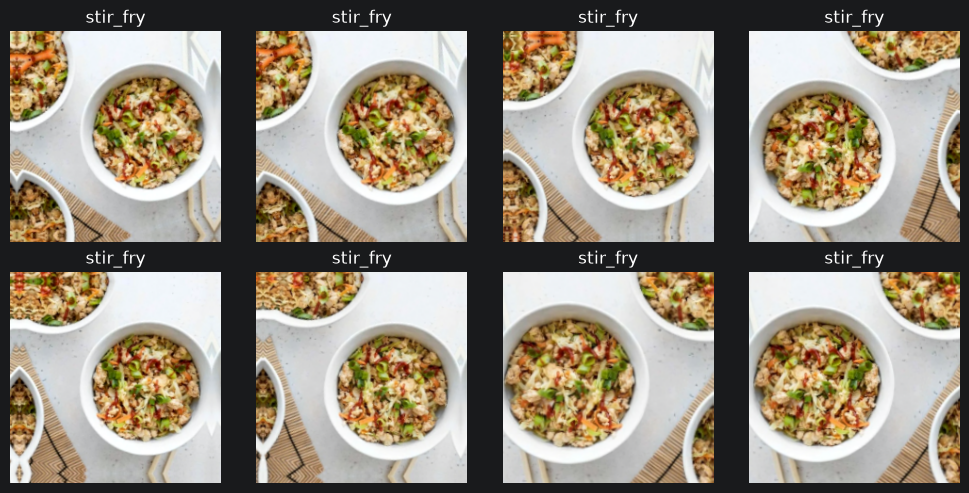

In [6]:
augmentation = tf.keras.Sequential([
    layers.RandomFlip("horizontal"),
    layers.RandomRotation(0.05),  # fraction of a full turn: 0.05 is 18 degrees
    layers.RandomZoom(0.1),
    layers.RandomContrast(0.1),
], name="augmentation")

show_images(
    [augmentation(images[:1], training=True)[0] for _ in range(8)],
    [CLASS_NAMES[labels[0]]] * 8,
)

### 3.2 Training

`train` compiles and fits a model with the same settings for every model.

- **Loss:** sparse categorical cross entropy on logits. Labels are integers, and every model ends in `Dense(6)` with no activation.
- **Optimizer:** Adam with a default learning rate of 0.001.
- **Class weights** from section 2.3.
- **Early stopping** on validation loss with a patience of 5 epochs. It restores the weights from the best epoch, so the returned model is the best one seen and not the last.

`plot_curves` draws training and validation accuracy and loss. The dotted line marks the epoch with the lowest validation loss, which is the epoch early stopping keeps.

In [7]:
def train(model, epochs=30, learning_rate=1e-3, patience=5):
    model.compile(
        optimizer=tf.keras.optimizers.Adam(learning_rate),
        loss=tf.keras.losses.SparseCategoricalCrossentropy(from_logits=True),
        metrics=["accuracy"],
    )
    early_stop = tf.keras.callbacks.EarlyStopping(
        monitor="val_loss", patience=patience, restore_best_weights=True
    )
    return model.fit(
        train_ds,
        validation_data=val_ds,
        epochs=epochs,
        class_weight=class_weight,
        callbacks=[early_stop],
    )


def plot_curves(history, title):
    h = history.history
    epochs = range(1, len(h["loss"]) + 1)
    best_epoch = int(np.argmin(h["val_loss"])) + 1

    fig, axes = plt.subplots(1, 2, figsize=(12, 4))
    for ax, metric in zip(axes, ["accuracy", "loss"]):
        ax.plot(epochs, h[metric], label="train")
        ax.plot(epochs, h[f"val_{metric}"], label="validation")
        ax.axvline(best_epoch, color="grey", linestyle=":", label=f"best epoch ({best_epoch})")
        ax.set(title=metric.capitalize(), xlabel="Epoch")
        ax.legend()
    fig.suptitle(title)
    plt.tight_layout()
    plt.show()

### 3.3 Evaluation

`evaluate` runs once per model on the test set and reports:

- accuracy and macro F1
- precision, recall and F1 per class
- a confusion matrix
- accuracy per source site

The site table checks for a shortcut. Site and class overlap in this dataset: sugarspunrun supplies about half of cake and cookies, and omnivorescookbook supplies most of stir fry. A model can score well by recognising a blog's photo style instead of the food. A large gap in accuracy between sites points to that.

Each result goes into `results` for the comparison in section 7.

In [8]:
site_of = pd.read_csv(ROOT / "data" / "split.csv").set_index("filename")["source_site"]
results = {}


def evaluate(model, ds, files, title):
    y_true = np.concatenate([y for _, y in ds])
    y_pred = model.predict(ds, verbose=0).argmax(axis=1)

    acc = accuracy_score(y_true, y_pred)
    macro_f1 = f1_score(y_true, y_pred, average="macro")
    print(f"{title}: accuracy {acc:.3f}, macro F1 {macro_f1:.3f}\n")
    print(classification_report(y_true, y_pred, target_names=CLASS_NAMES, digits=3, zero_division=0))

    ConfusionMatrixDisplay.from_predictions(
        y_true, y_pred, display_labels=CLASS_NAMES, xticks_rotation=45, cmap="Blues", colorbar=False
    )
    plt.title(title)
    plt.show()

    per_site = (
        pd.DataFrame({"site": site_of[[Path(f).name for f in files]].values, "correct": y_true == y_pred})
        .groupby("site")["correct"]
        .agg(accuracy="mean", images="size")
        .sort_values("accuracy")
    )
    display(per_site.round(3))

    return {"accuracy": acc, "macro F1": macro_f1, "parameters": model.count_params()}

## 4. Model 0: naive baseline

A deliberately simple model: one conv block, then `Flatten` into a dense layer, with no augmentation. It answers one question: what happens with no design for this dataset? It sets the floor that Model 1 has to beat, and its failure gives a concrete reason for each choice in Model 1.

In [9]:
tf.keras.utils.set_random_seed(SEED)

model0 = tf.keras.Sequential([
    tf.keras.Input(shape=INPUT_SHAPE),
    layers.Rescaling(1 / 255),
    layers.Conv2D(32, 3, activation="relu"),
    layers.MaxPooling2D(),
    layers.Flatten(),
    layers.Dense(128, activation="relu"),
    layers.Dense(NUM_CLASSES),
], name="model0")

model0.summary()

Model: "model0"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ rescaling (Rescaling)           │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 222, 222, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 111, 111, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 394272)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │    50,466,944 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 6)              │           774 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 50,468,614 (192.52 MB)

 Trainable params: 50,468,614 (192.52 MB)

 Non-trainable params: 0 (0.00 B)

In [10]:
history0 = train(model0)

Epoch 1/30


/Users/demiladeakin/Developer/tme_6015_assignment_2/.venv/lib/python3.12/site-packages/keras/src/trainers/epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


37/37 ━━━━━━━━━━━━━━━━━━━━ 6s 147ms/step - accuracy: 0.1677 - loss: 6.4024 - val_accuracy: 0.2222 - val_loss: 1.7503
Epoch 2/30
37/37 ━━━━━━━━━━━━━━━━━━━━ 5s 131ms/step - accuracy: 0.3983 - loss: 1.5206 - val_accuracy: 0.3611 - val_loss: 1.6164
Epoch 3/30
37/37 ━━━━━━━━━━━━━━━━━━━━ 6s 153ms/step - accuracy: 0.7591 - loss: 0.9290 - val_accuracy: 0.4087 - val_loss: 1.4929
Epoch 4/30
37/37 ━━━━━━━━━━━━━━━━━━━━ 5s 147ms/step - accuracy: 0.9532 - loss: 0.2776 - val_accuracy: 0.4484 - val_loss: 1.6920
Epoch 5/30
37/37 ━━━━━━━━━━━━━━━━━━━━ 5s 132ms/step - accuracy: 0.9957 - loss: 0.0464 - val_accuracy: 0.4524 - val_loss: 1.6850
Epoch 6/30
37/37 ━━━━━━━━━━━━━━━━━━━━ 5s 138ms/step - accuracy: 1.0000 - loss: 0.0083 - val_accuracy: 0.4603 - val_loss: 1.7644
Epoch 7/30
37/37 ━━━━━━━━━━━━━━━━━━━━ 5s 137ms/step - accuracy: 1.0000 - loss: 0.0027 - val_accuracy: 0.4603 - val_loss: 1.8542
Epoch 8/30
37/37 ━━━━━━━━━━━━━━━━━━━━ 5s 132ms/step - accuracy: 1.0000 - loss: 0.0015 - val_accuracy: 0.4444 - val_

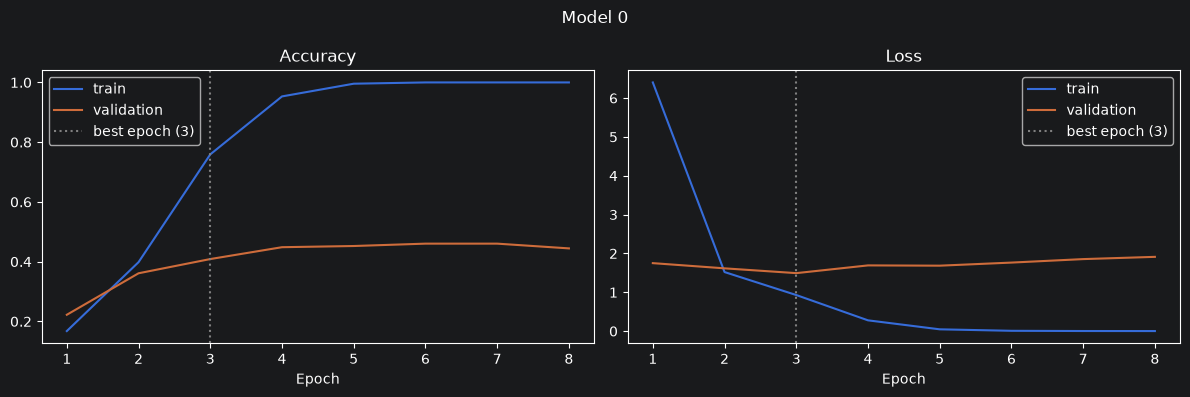

In [11]:
plot_curves(history0, "Model 0")

### Model 0 results

_Write your interpretation here: where training and validation split, what the parameter count in the summary says about it, and which part of the design causes it._

In [ ]:
results["Model 0"] = evaluate(model0, test_ds, test_files, "Model 0")

## 5. Model 1: CNN from scratch

_To do._

## 6. Model 2: transfer learning

_To do._

## 7. Comparison

Architecture, hyperparameters, training curves and test results side by side.

In [ ]:
pd.DataFrame(results).T.astype({"parameters": int}).round(3)

## 8. Use of generative AI

_Running notes for item 5. Rewrite in your own words._

- Claude helped design the data loader, the class weight formula and the augmentation block.
- Claude reviewed the first Model 0 cells and pointed out a rescaling typo (1/225), a model rebuilt after compiling, and a Keras F1 metric that does not work with integer labels.
- Claude restructured this notebook into shared functions and sections.